# PyTorch ile Yapay Sinir Agi Siniflandirmasi

## 1. Siniflandirma Veri Seti Hazirlama

In [421]:
from sklearn.datasets import make_circles
import torch
from sympy import Circle

n_samples = 1000 # 1000 tane olsun nokta olucak

X, y = make_circles(n_samples, noise=0.03, random_state=42) # noise karmasiklik gibi


len(X), len(y) # boyutlari iste 1000 tane olusturdu

(1000, 1000)

In [422]:
print(f"X in ilk bes elemani: \n{X[:5]} " )
print(f"y nin ilk bes elemani:\n {y[:5]}")

X in ilk bes elemani: 
[[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]] 
y nin ilk bes elemani:
 [1 1 1 1 0]


In [423]:
#pandas kullanarak bakalim veri setine
import pandas as pd

df = pd.DataFrame({'x1': X[:, 0], 'x2': X[:, 1], 'y': y})
df.head(10)

,x1,x2,y
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


Text(0.5, 1.0, 'Cember Veri Seti')

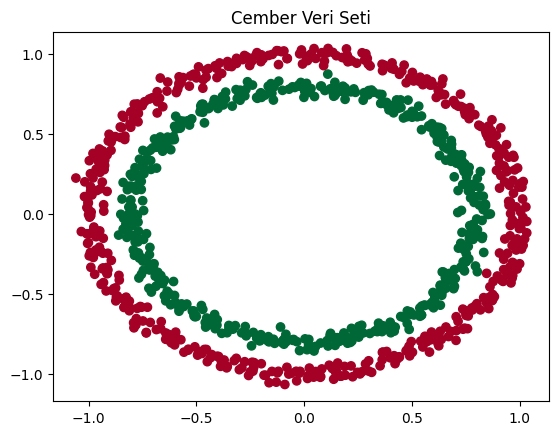

In [424]:
# veri setini gorsellestirelim
from matplotlib import pyplot as plt

plt.scatter(X[:, 0], X[:, 1], c=y, cmap='RdYlGn')
plt.title("Cember Veri Seti")

## 1.1 Girdi Ve  Cikti Sekillerine Bakma

In [425]:
X.shape, y.shape # x ve y tarafinin sekli x  x1 ve x2 de y sadece y den olusuyor

((1000, 2), (1000,))

In [426]:
X

array([[ 0.75424625,  0.23148074],
       [-0.75615888,  0.15325888],
       [-0.81539193,  0.17328203],
       ...,
       [-0.13690036, -0.81001183],
       [ 0.67036156, -0.76750154],
       [ 0.28105665,  0.96382443]], shape=(1000, 2))

In [427]:
X_sample = X[0]
y_smaple = y[0]

print(f"x in ilk degeri : {X_sample}, y nin ilk degeri : {y_smaple}")
print(f"x in veri sekli {X_sample.shape}, y nin veri sekli  : {y_smaple}")

x in ilk degeri : [0.75424625 0.23148074], y nin ilk degeri : 1
x in veri sekli (2,), y nin veri sekli  : 1


In [428]:
import torch

torch.__version__

'2.8.0'

In [429]:
type(X), X.dtype # olusturlan verinin data type float64 torch dtype olarak float32 kullaniyor

(numpy.ndarray, dtype('float64'))

In [430]:
# Tensorlere cevirme
X = torch.tensor(X, dtype=torch.float)
y = torch.tensor(y, dtype=torch.float)
type(X), X.dtype # goruldugu uzere float32

(torch.Tensor, torch.float32)

In [431]:
# test train olarak bolme
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # %20 test olucak sekilde bolduk
len(X_train), len(X_test), len(y_train), len(y_test)

(800, 200, 800, 200)

## 2. Modeli Insaat Etmek

Kirmizi ve Mavi noktalari ayirmak icin modeli insaat edelim

1. Cihazin ne uzerinde calisicagini ayarlayalim (cpu, gpu)
2. Bir model olusturalim
3. Kayip fonksiyonu ve optimizer tanimlayalim
4. Egitim ve test dongsu olusturalim

In [432]:
import torch
from torch import nn

device = "mps" if torch.mps.is_available() else "cpu" # apple silicon kullandigim icin mps kullaniyorum
torch.mps.manual_seed(42) # buna gerek de yok apple da gpu ve cpu ayni hafizayi kullaniyor
torch.manual_seed(42)

In [433]:
X_train

tensor([[ 0.6579, -0.4651],
        [ 0.6319, -0.7347],
        [-1.0086, -0.1240],
        ...,
        [ 0.0157, -1.0300],
        [ 1.0110,  0.1680],
        [ 0.5578, -0.5709]])

In [434]:
# nn.Module kullaniyoruz modeli olsuturmak icin
class CircleModel0(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer_1 = nn.Linear(2, 5) # 2 -> 5
        self.layer_2 = nn.Linear(5, 1) # 5 -> 1



    def forward(self, x):

        return self.layer_2(self.layer_1(x)) # forward hesplanmasi buraka

model_0 = CircleModel0().to(device) # mps yukluyor
model_0

CircleModel0(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)


### 2.1 Kayıp (Loss) Fonksiyonu ve Optimize Edici (Optimizer) Kurulumu

Hangi loss fonksiyonunu veya optimizer’ı kullanmalısın?

Bunun cevabı *probleme özeldir.*

* Eğer **regresyon** problemi yapıyorsan, **MAE (Mean Absolute Error)** veya **MSE (Mean Squared Error)** kullanabilirsin.
* Eğer **sınıflandırma (classification)** problemi yapıyorsan, **Binary Cross Entropy** veya **Categorical Cross Entropy** (kısaca Cross Entropy) kullanılır.

Hatırlatma: **Loss fonksiyonu**, modelinin tahminlerinin ne kadar *yanlış* olduğunu ölçer.

**Optimizer** olarak ise en yaygın kullanılanlar **SGD** ve **Adam**’dır. Ancak PyTorch içinde daha birçok seçenek mevcuttur.


**Bazı yaygın loss fonksiyonları ve optimizer örnekleri için:**
[https://www.learnpytorch.io/02_pytorch_classification/#21-setup-loss-function-and-optimizer](https://www.learnpytorch.io/02_pytorch_classification/#21-setup-loss-function-and-optimizer)

Bu örnekte **loss fonksiyonu olarak** `torch.nn.BCEWithLogitsLoss()` kullanacağız.
Binary Cross Entropy (BCE) nedir daha detaylı öğrenmek istersen:
[https://towardsdatascience.com/understanding-binary-cross-entropy-log-loss-a-visual-explanation-a3ac6025181a](https://towardsdatascience.com/understanding-binary-cross-entropy-log-loss-a-visual-explanation-a3ac6025181a)

“Logit” teriminin derin öğrenmedeki anlamı için:
[https://stackoverflow.com/a/52111173/7900723](https://stackoverflow.com/a/52111173/7900723)

PyTorch içindeki farklı optimizer’lar için: `torch.optim`




In [435]:
loss_f = nn.BCEWithLogitsLoss() # ikili siniflandirma oldugu icin binary cross entropi kullaniyoruz
optimizer = torch.optim.SGD(model_0.parameters(), lr=0.01) # SGD guzel bir optimizasyon sunuyor bize learnin rate 0.01

In [436]:
def accuracy_fn(y_true, y_pred): # dogruluk hesaplama icin kullaniyoruz
    correct = torch.eq(y_pred, y_true).sum().item()
    return correct / len(y_pred) *100


### 3. Modeli Eğitme

Modelimizi eğitmek için aşağıdaki adımlardan oluşan bir **training loop (eğitim döngüsü)** kurmamız gerekiyor:

1. **Forward pass (ileriye doğru geçiş)**
2. **Loss’u hesapla**
3. **Optimizer zero grad (gradyanları sıfırla)**
4. **Loss backward (geri yayılım/backpropagation)**
5. **Optimizer step (gradient descent adımı)**

---

### 3.1 Logit → Olasılık → Tahmin Etiketi Dönüşümü

Modelimizin çıktıları **ham logit değerleri** olacak.

Bu logits’leri **aktivasyon fonksiyonuna** vererek **olasılık tahminlerine** dönüştürebiliriz:

* **Binary classification** için → `sigmoid`
* **Multiclass classification** için → `softmax`

Daha sonra modelin verdiği **olasılıkları etiketlere çevirmek için**:

* **Binary classification** ise → `round()` (0 veya 1’e yuvarlama)
* **Multiclass classification** ise → `argmax()` (en yüksek değeri seçme)



In [437]:
model_0.eval() # gradyan yani turevini almasini kapatiyoruz agirliklari guncellemesin die
with torch.inference_mode():
  y_logits = model_0(X_test.to(device))[:5]
y_logits # cikti deger boyle ama biz ciktiyi 1. 0. olarak almak istiyoruz

tensor([[-0.1269],
        [-0.0967],
        [-0.1908],
        [-0.1089],
        [-0.1667]], device='mps:0')

In [438]:
y_test[: 5]

tensor([1., 0., 1., 0., 1.])

In [439]:
# Modelimizin logit çıktıları üzerine sigmoid aktivasyon fonksiyonunu uygulayarak bunları tahmin olasılıklarına dönüştür.
y_pred_probs = torch.sigmoid(y_logits) # 0 ve 1 icin daha mantikli ayirmaya donusturuyor
y_pred_probs

tensor([[0.4683],
        [0.4758],
        [0.4524],
        [0.4728],
        [0.4584]], device='mps:0')

In [440]:
# Degerleri 1 ve 0 a donusturuyor
y_pred = torch.round(y_pred_probs) # 0.5 buyukse 1 kucukse 0
y_pred_labels = torch.round(torch.sigmoid(model_0(X_test.to(device))[:5])) # boylede kullanabilirsin

print(torch.eq(y_pred.squeeze(), y_pred_labels.squeeze())) # cikti ayni



tensor([True, True, True, True, True], device='mps:0')


In [441]:
y_test[:5]


tensor([1., 0., 1., 0., 1.])

In [442]:
# Rastgeleligi karma yapmiyorum
torch.manual_seed(42)

# veriyi mps e atiyor
X_train, X_test = X_train.to(device), X_test.to(device)
y_train, y_test = y_train.to(device), y_test.to(device)

epochs = 10000 # epoch 10000 olarak ayarladik

for epoch in range(epochs):
    model_0.train() # egitim icin baslattik
    y_logits = model_0(X_train).squeeze() # veriyi modele verdik ve logit degerini aldik

    y_pred = torch.round(torch.sigmoid(y_logits)) # burada da 0. ve 1. donusuruyor

    loss = loss_f(y_logits, y_train) # burada y_logit ile gercek degeri loss fonkisyonu ile hesapliyor

    acc = accuracy_fn(y_train, y_pred) # pred ile gercek degeri hesapliyor 0. 1. olanlari

    optimizer.zero_grad()

    loss.backward() # geri yayilim yapiyor

    optimizer.step() # gradyanlari hesapliyor

    model_0.eval() # hesaplama modundan cikiliyor tahmine geciliyor drop gibi

    with torch.inference_mode(): # tahmin modu

        test_logits = model_0(X_test).squeeze() # test verisi modele veriliyor
        test_pred = torch.round(torch.sigmoid(test_logits)) # prediction hesaplandi
        test_loss = loss_f(test_logits, y_test) # test loss degeri
        test_accuracy = accuracy_fn(y_test, test_pred) # test dogruluk degeri

    if epoch % 1000 == 0:
        print(f"Epoch: {epoch}, Train_Loss: {loss}, Train_Dogruluk: {acc}, Test_Dogruluk: {test_accuracy}, Test Loss: {test_loss}")




Epoch: 0, Train_Loss: 0.6956854462623596, Train_Dogruluk: 50.0, Test_Dogruluk: 50.0, Test Loss: 0.697385311126709
Epoch: 1000, Train_Loss: 0.693022608757019, Train_Dogruluk: 50.5, Test_Dogruluk: 46.5, Test Loss: 0.6954260468482971
Epoch: 2000, Train_Loss: 0.6929898262023926, Train_Dogruluk: 51.37500000000001, Test_Dogruluk: 46.5, Test Loss: 0.6950356960296631
Epoch: 3000, Train_Loss: 0.6929821968078613, Train_Dogruluk: 51.24999999999999, Test_Dogruluk: 45.5, Test Loss: 0.6948500275611877
Epoch: 4000, Train_Loss: 0.6929803490638733, Train_Dogruluk: 51.125, Test_Dogruluk: 45.5, Test Loss: 0.6947617530822754
Epoch: 5000, Train_Loss: 0.6929799914360046, Train_Dogruluk: 51.37500000000001, Test_Dogruluk: 46.0, Test Loss: 0.6947192549705505
Epoch: 6000, Train_Loss: 0.6929798722267151, Train_Dogruluk: 51.125, Test_Dogruluk: 46.0, Test Loss: 0.6946988105773926
Epoch: 7000, Train_Loss: 0.6929798126220703, Train_Dogruluk: 51.125, Test_Dogruluk: 46.0, Test Loss: 0.6946888566017151
Epoch: 8000, Tra

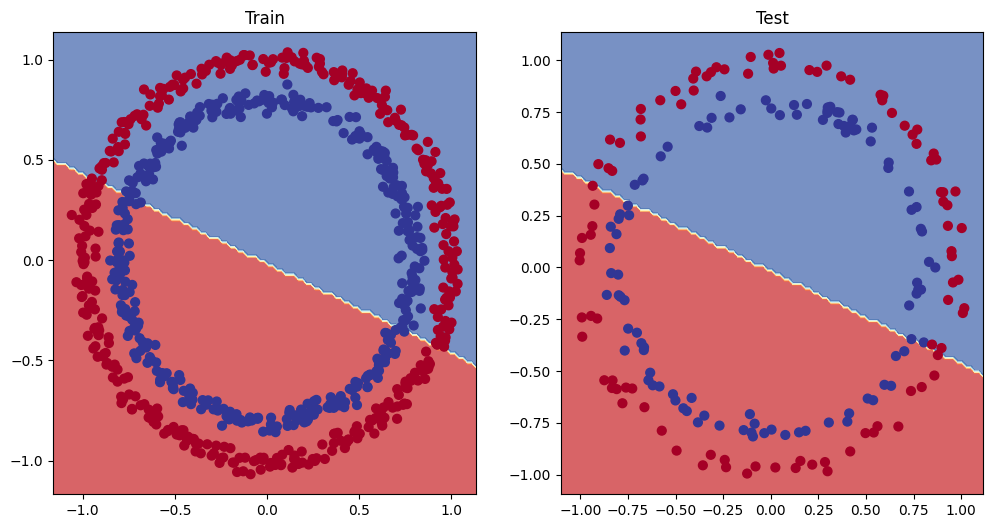

In [443]:
# Bu help icin veri setini gorselestirmek icin kod yazamiza gerek kalmiyor
from helper_functions import plot_predictions, plot_decision_boundary

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1) # train icin gorsel
plt.title("Train")
plot_decision_boundary(model_0, X_train, y_train)
plt.subplot(1, 2, 2) # test icin gorsel
plt.title("Test")
plot_decision_boundary(model_0, X_test, y_test)



## Model_0 Sonuc

Sonuc gorudugu gibi tatmin edici degil cunku burada linear bi calisma yaptik veri setini de ortadan ikiye ayirdi goruldugu gibi bu yuzden dogruluk %50 civari cikiyor ama veri seti ic ice ortadan bir cember benzeri bir sekil ile veri seti iki parcaya ayrilmasi gerekiyor

### Ne Yapilmasi lazim ?:

* Linear yerine non-linear bir model yaratmamiz gerekiyor

### Peki Modeli gelistirmek icin ne Yapilabilir

* Daha fazla katman ekleyeme - Suan 2 katmandan olusuyor
* Katmandaki gizli birim sayisini cogaltma -  5 ten 10 yap
* Daha fazla egitme
* Aktivasyon fonksiyonunu degistirme
* Learning Rate degistirme
* Loss fonksiyonunu degistirrme

## Linear Tahmin

In [444]:
# Linear tahmin icin veri seti kullanicam
from sklearn.datasets import make_regression
X, y = make_regression(n_samples=1000, n_features=1, noise=1, random_state=42,)

In [445]:
# Veri setini test ve train olmak uzere ayirdim Test %20
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train, X_test  = torch.tensor(X_train, dtype=torch.float), torch.tensor(X_test, dtype=torch.float)
y_train, y_test = torch.tensor(y_train, dtype=torch.float), torch.tensor(y_test, dtype=torch.float)

In [446]:
class LinearReg(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=1, out_features=5) # 1-> 5
        self.layer_2 = nn.Linear(in_features=5, out_features=1)# 5 -> 1

    def forward(self, x):
        return self.layer_2(self.layer_1(x))

reg_1 = LinearReg().to(device)
reg_1.state_dict()

OrderedDict([('layer_1.weight',
              tensor([[ 0.7645],
                      [ 0.8300],
                      [-0.2343],
                      [ 0.9186],
                      [-0.2191]], device='mps:0')),
             ('layer_1.bias',
              tensor([ 0.2018, -0.4869,  0.5873,  0.8815, -0.7336], device='mps:0')),
             ('layer_2.weight',
              tensor([[0.3887, 0.0837, 0.3304, 0.0606, 0.2156]], device='mps:0')),
             ('layer_2.bias', tensor([-0.0631], device='mps:0'))])

In [447]:
loss_fn = nn.MSELoss() # loss fonksiyonum ortalama kare hatasi
optimizer = torch.optim.SGD(reg_1.parameters(), lr=0.01) # optimizer olarak SGD kullaniyorum

In [448]:
# Veriyi buradada apple silicon kullandigim icin device olarak veriyi mps kullanicagini gosterdim
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

In [449]:
epochs = 100 # 100 epouch bu veri icin cok bile
for epoch in range(epochs):
    reg_1.train() # Train oarak baslattik

    y_pred = reg_1(X_train).squeeze() # model ciktisi

    loss = loss_fn(y_pred, y_train) # gercek deger ile aradaki farki aliyor

    optimizer.zero_grad()

    loss.backward() # Geri yayilim baslattik

    optimizer.step() # Gradyanlari hesapliyor


    reg_1.eval() # Gradyanlari hesaplatmayi durdurduk

    with torch.inference_mode(): # tahmin modunda
        test_pred = reg_1(X_test).squeeze()  # Test verisini modele verdik
        test_loss = loss_fn(test_pred, y_test) # test loss degerine ulastik



    print(f"Epoch: {epoch}, Train_Loss: {loss} Test Loss: {test_loss}")


Epoch: 0, Train_Loss: 254.72265625 Test Loss: 253.47972106933594
Epoch: 1, Train_Loss: 230.20269775390625 Test Loss: 221.49461364746094
Epoch: 2, Train_Loss: 201.3447265625 Test Loss: 179.7961883544922
Epoch: 3, Train_Loss: 163.66519165039062 Test Loss: 128.6990509033203
Epoch: 4, Train_Loss: 117.4180679321289 Test Loss: 75.99176788330078
Epoch: 5, Train_Loss: 69.61632537841797 Test Loss: 34.571590423583984
Epoch: 6, Train_Loss: 31.929946899414062 Test Loss: 11.912788391113281
Epoch: 7, Train_Loss: 11.186046600341797 Test Loss: 3.6693778038024902
Epoch: 8, Train_Loss: 3.5348870754241943 Test Loss: 1.5853781700134277
Epoch: 9, Train_Loss: 1.5340728759765625 Test Loss: 1.1661721467971802
Epoch: 10, Train_Loss: 1.0958876609802246 Test Loss: 1.0881812572479248
Epoch: 11, Train_Loss: 0.996482253074646 Test Loss: 1.0744212865829468
Epoch: 12, Train_Loss: 0.9695625901222229 Test Loss: 1.0732113122940063
Epoch: 13, Train_Loss: 0.9608505964279175 Test Loss: 1.0743982791900635
Epoch: 14, Train_L

### Test Verisini Gorsellestirelim

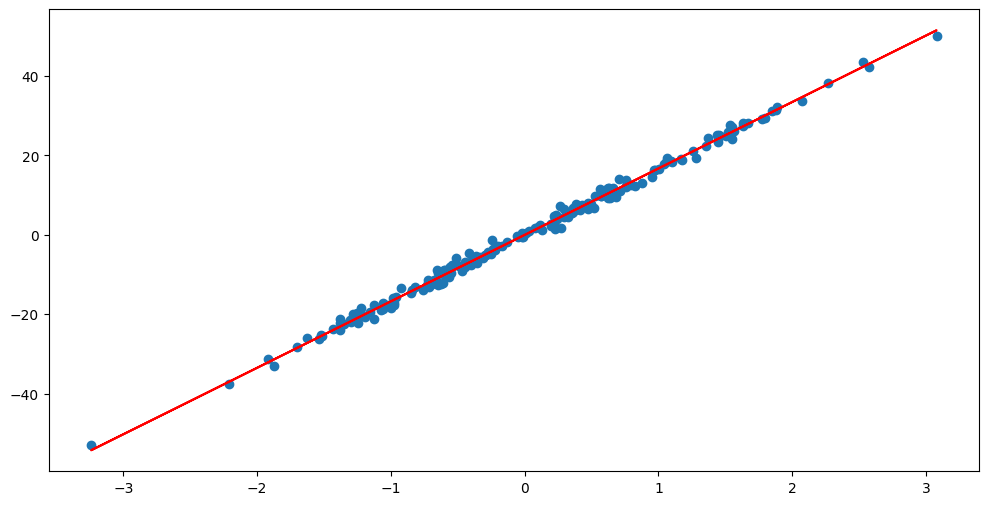

In [450]:
# Tes Verisi ve sonucu gorsellestirelim
plt.figure(figsize=(12, 6))
plt.scatter(X_test.cpu(), y_test.cpu())
plt.plot(X_test.cpu(), reg_1(X_test).detach().cpu(), color="red")


## Inceleme

Goruldugu uzere model_0 da kotu sonuc almamizin sebebi linear bi aktivasyon kullanmamiz ama linear bir veride bu islem cok ama cok dogru sonuc veriyor goruldugu uzere

### CircleModelV1 Gecme Zamani

* Non-linear bir aktivasyon yapmak
* Ara katman sayisini artirmak
* katmandaki features lari artirmak



In [451]:
# Tekrardan veri setini import ediyorum
from sklearn.datasets import make_circles
X, y = make_circles(n_samples=1000, noise=0.03, random_state=42)

In [452]:
# Test ve Train olarak ayiriyoum
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_test = torch.tensor(X_train, dtype= torch.float32), torch.tensor(X_test, dtype= torch.float32)
y_train, y_test = torch.tensor(y_train, dtype= torch.float32), torch.tensor(y_test, dtype= torch.float32)


In [453]:
from torch import nn
# Yeni Modelimizi Yaratalim
class CircleModelV1(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(2, 10) # 2 -> 10
        self.layer_2 = nn.Linear(10, 10) # 10 -> 10
        self.layer_3 = nn.Linear(10, 1) # 10 -> 1
        self.relu = nn.ReLU() # onemli kisim non linear donusturuyoruz

    def forward(self, x):

        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))
        # 2->10->relu->10->10->relu->10->1
model_1 = CircleModelV1().to(device)
model_1.state_dict()

OrderedDict([('layer_1.weight',
              tensor([[ 0.5451,  0.1045],
                      [-0.3301,  0.1802],
                      [-0.3258, -0.0829],
                      [-0.2872,  0.4691],
                      [-0.5582, -0.3260],
                      [-0.1997, -0.4252],
                      [ 0.0667, -0.6984],
                      [ 0.6386, -0.6007],
                      [ 0.5459,  0.1177],
                      [-0.2296,  0.4370]], device='mps:0')),
             ('layer_1.bias',
              tensor([ 0.1102,  0.5713,  0.0773, -0.2230,  0.1900, -0.1918,  0.2976,  0.6313,
                       0.4087, -0.3091], device='mps:0')),
             ('layer_2.weight',
              tensor([[ 0.1825,  0.0566,  0.1606, -0.1927, -0.3130, -0.1222, -0.2426,  0.2595,
                        0.0911,  0.1310],
                      [ 0.1000, -0.0055,  0.2475, -0.2247,  0.0199, -0.2158,  0.0975, -0.1089,
                        0.0969, -0.0659],
                      [ 0.2623, -0.1874,

In [454]:
loss_fn = nn.BCEWithLogitsLoss() # loss fonkisyonunu yaraltalim
optimizer = torch.optim.SGD(model_1.parameters(), lr=0.01) # SGD iyidir

In [455]:
# Apple silicon kullandigim icin veriyi mps atiyorum
X_train, X_test = X_train.to(device), X_test.to(device)
y_train, y_test = y_train.to(device), y_test.to(device)

In [456]:
epochs = 15000 # anca yeter
for epoch in range(epochs):

    model_1.train() # train olarak baslatiyoruz

    y_logits = model_1(X_train).squeeze() # modelden aldigimiz cikti ama kotu bunu biz binary olamsi icin sigmoid kullaniyoruz

    y_pred = torch.round(torch.sigmoid(y_logits)) # if y_logits < 0.5 == 0. else 1.

    loss = loss_fn(y_logits, y_train) # loss hesaplayalim

    acc = accuracy_fn(y_train, y_pred) # dogruluk hesaplamasi

    optimizer.zero_grad()

    loss.backward() # Geri yayilim yapsin modele

    optimizer.step() # gradyanlari degstirsin

    model_1.eval() # tahmin icin gradyan hesplamasini durduruyorum
    with torch.inference_mode(): # tahmin modu

        test_logits = model_1(X_test).squeeze() # modelin test verisi uzerindeki ciktisi

        test_pred = torch.round(torch.sigmoid(test_logits))

        test_loss = loss_fn(test_logits, y_test)

        test_accuracy = accuracy_fn(y_test, test_pred)

    if epoch % 1000 == 0:
        # Loss degerlerini dusurelim :)
        print(f"Epoch: {epoch}, Train_Loss: {loss}, Train_Dogruluk: {acc}, Test_Dogruluk: {test_accuracy}, Test Loss: {test_loss}")

Epoch: 0, Train_Loss: 0.6960331797599792, Train_Dogruluk: 50.0, Test_Dogruluk: 46.0, Test Loss: 0.6946464776992798
Epoch: 1000, Train_Loss: 0.6938386559486389, Train_Dogruluk: 50.125, Test_Dogruluk: 44.0, Test Loss: 0.6934663653373718
Epoch: 2000, Train_Loss: 0.6925033330917358, Train_Dogruluk: 51.24999999999999, Test_Dogruluk: 51.0, Test Loss: 0.6929572224617004
Epoch: 3000, Train_Loss: 0.6910568475723267, Train_Dogruluk: 54.125, Test_Dogruluk: 54.0, Test Loss: 0.6923781037330627
Epoch: 4000, Train_Loss: 0.6891458034515381, Train_Dogruluk: 60.5, Test_Dogruluk: 57.49999999999999, Test Loss: 0.6914923191070557
Epoch: 5000, Train_Loss: 0.6861693859100342, Train_Dogruluk: 62.74999999999999, Test_Dogruluk: 57.49999999999999, Test Loss: 0.6895146369934082
Epoch: 6000, Train_Loss: 0.6814123392105103, Train_Dogruluk: 63.87500000000001, Test_Dogruluk: 61.0, Test Loss: 0.6855912804603577
Epoch: 7000, Train_Loss: 0.6742120385169983, Train_Dogruluk: 68.5, Test_Dogruluk: 66.5, Test Loss: 0.6792747

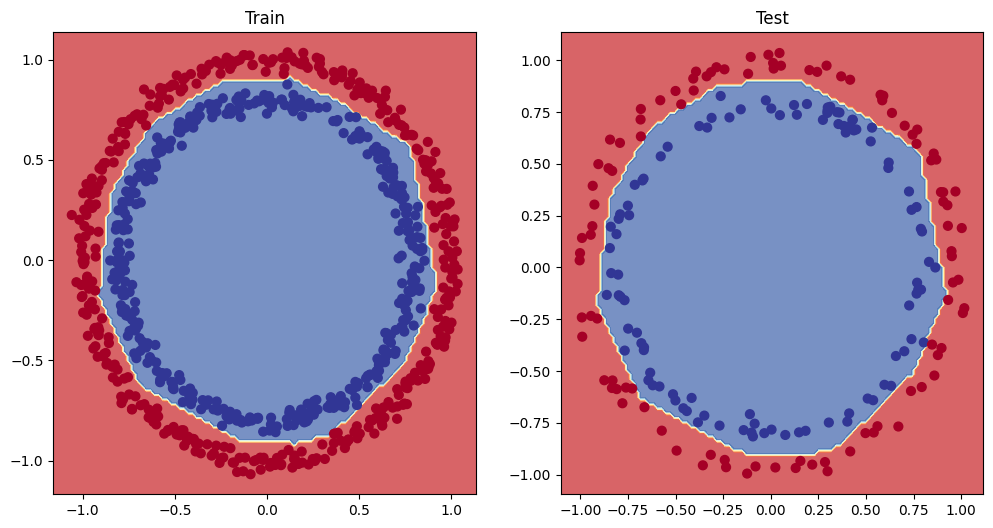

In [457]:
# Bu help icin veri setini gorselestirmek icin kod yazamiza gerek kalmiyor
from helper_functions import plot_predictions, plot_decision_boundary

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1) # train icin gorsel
plt.title("Train")
plot_decision_boundary(model_1, X_train, y_train)
plt.subplot(1, 2, 2) # test icin gorsel
plt.title("Test")
plot_decision_boundary(model_1, X_test, y_test)



### HAHAHA
Goruldugu uzere non-linear bi aktivasyon kullanarak modelimizi istedigimiz sonuclari elde ettik modelimiz Test verisini 100/100 dogru biliyor

Gordun `nn.ReLU()` gucu iste boyle

## Multiclassification Uzerinde Calisalim


* Binary classification icin → `sigmoid`
* Multiclass classification için → `softmax`

### Modelin ciktilarini siniflara ayirmak icin

* Binary classification ise → `round()` (0 veya 1 e yuvarlama)
* Multiclass classification ise → `argmax()` (en yuksek degeri secme)

In [458]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=1000, n_features=2, random_state=42, centers=4) # 4 sinifi olan bir veri seti olusturdum
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Veri setinin neye benzedigine bakalim

Text(0.5, 1.0, 'Test')

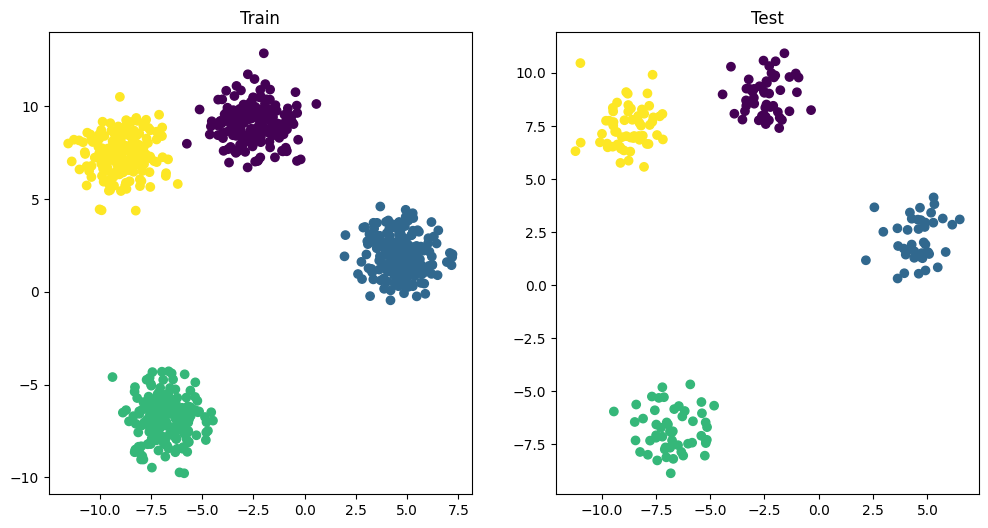

In [459]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train)
plt.title("Train")
plt.subplot(1, 2, 2)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test)
plt.title("Test")

In [460]:
# Diziyi tensore cevirdim
X_train, X_test = torch.tensor(X_train, dtype=torch.float), torch.tensor(X_test, dtype=torch.float)
y_train, y_test = torch.tensor(y_train, dtype=torch.float), torch.tensor(y_test, dtype=torch.float)

In [461]:
# Modelimizi olsuturalim
class Blobsv1(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(2, 10)
        self.layer_2 = nn.Linear(10, 10)
        self.layer_3 = nn.Linear(10, 4) # 4 sinif oldugu icin cikisi 4 olarak belirledim
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

model_2 = Blobsv1().to(device)
model_2.state_dict()

OrderedDict([('layer_1.weight',
              tensor([[ 0.6074,  0.1576],
                      [-0.3912, -0.3579],
                      [-0.0338,  0.3948],
                      [-0.1807, -0.4035],
                      [-0.2421, -0.5283],
                      [ 0.2522,  0.5473],
                      [-0.6657,  0.1642],
                      [ 0.3653,  0.1282],
                      [-0.2518,  0.3691],
                      [ 0.3716,  0.2644]], device='mps:0')),
             ('layer_1.bias',
              tensor([-0.1243, -0.1872,  0.0756, -0.1249, -0.2107,  0.4520,  0.6077, -0.0700,
                      -0.1583,  0.0103], device='mps:0')),
             ('layer_2.weight',
              tensor([[-0.0189,  0.0760,  0.0886, -0.2872, -0.1167,  0.2663,  0.1232, -0.0157,
                       -0.1907, -0.1935],
                      [-0.2833, -0.1031,  0.1068,  0.2016,  0.1460, -0.2795, -0.1902, -0.0499,
                        0.3059,  0.0457],
                      [-0.0819,  0.1308,

In [462]:
loss_fn = nn.CrossEntropyLoss() # loss fonkisyonunu olusturdum coklu siniflarda bu loss fonkisyonunu kullanmak en dogrusu
optimizer = torch.optim.AdamW(model_2.parameters(), lr=0.01) # bol sinif olucagi icin AdamW sectim

In [463]:
X_train, X_test = X_train.to(device), X_test.to(device)
y_train, y_test = y_train.to(device), y_test.to(device)

In [464]:
epochs = 100

for epoch in range(epochs):

    model_2.train() # train olraka modeli baslatalim

    y_logits = model_2(X_train).squeeze() # modelin cikisi

    y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1) # burada sunu yapiyoruz [0.11 , 0.323, 0.22, 0.44] diye cikti var burada maksimumu aliyoruz ve sinif olarak veriyor 3 mu 1 bi 0 mi die

    loss = loss_fn(y_logits, y_train) # loss degerini hesapla

    acc = accuracy_fn(y_train, y_pred) # dogruluk

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model_2.eval()
    with torch.inference_mode():

        test_logits = model_2(X_test).squeeze()

        test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)

        test_loss = loss_fn(test_logits, y_test)

        test_accuracy = accuracy_fn(y_test, test_pred)

    print(f"Epoch {epoch}, Train loss: {loss}, Train accuracy: {acc}, Test loss: {test_loss}, Test accuracy: {test_accuracy}")



Epoch 0, Train loss: 1.4296249151229858, Train accuracy: 35.625, Test loss: 1.334968090057373, Test accuracy: 56.99999999999999
Epoch 1, Train loss: 1.3271194696426392, Train accuracy: 54.37499999999999, Test loss: 1.2449734210968018, Test accuracy: 62.0
Epoch 2, Train loss: 1.2382457256317139, Train accuracy: 65.0, Test loss: 1.166532039642334, Test accuracy: 69.0
Epoch 3, Train loss: 1.1596689224243164, Train accuracy: 72.125, Test loss: 1.1058048009872437, Test accuracy: 71.0
Epoch 4, Train loss: 1.0967565774917603, Train accuracy: 75.0, Test loss: 1.0471041202545166, Test accuracy: 73.0
Epoch 5, Train loss: 1.0360379219055176, Train accuracy: 76.625, Test loss: 0.9905779361724854, Test accuracy: 78.5
Epoch 6, Train loss: 0.9769139289855957, Train accuracy: 81.625, Test loss: 0.9347479343414307, Test accuracy: 88.0
Epoch 7, Train loss: 0.9190385341644287, Train accuracy: 90.125, Test loss: 0.8794188499450684, Test accuracy: 93.0
Epoch 8, Train loss: 0.8617832660675049, Train accurac

### Bakalim sonuclar nasil

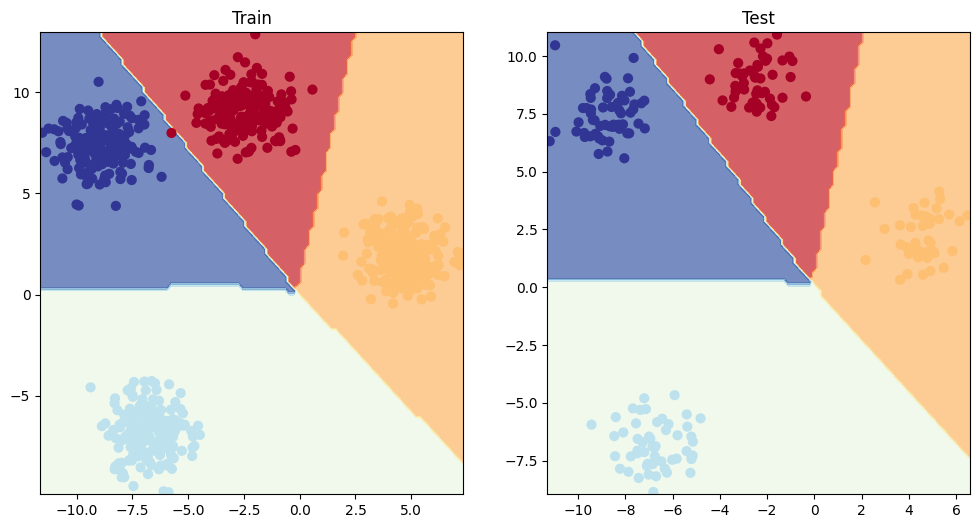

In [465]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_2, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_2, X_test, y_test)

In [466]:

from torchmetrics import Accuracy

# Setup metric
torchmetric_accuracy = Accuracy(task="multiclass", num_classes=4).to(device)

# Calculuate accuracy
torchmetric_accuracy(test_pred, y_test)

tensor(1., device='mps:0')